# Ejercicio 1
![[Pasted image 20260401123356.png]]
## Explicacion del problema
Se trata del [[Metodo de Eliminacion de Gauss]]
## Solucion Analitica
## Pseudo-Codigo
```
INICIO

  // --- PASO 1: PREPARACIÓN ---
  Definir Matriz A (4x4)
  Definir Vector B (4x1)
  Crear Matriz_Aumentada combinando [A, B] (será de 4x5)
  'n' = número de filas de A (en este caso, 4)

  // --- PASO 2: TRIANGULACIÓN (Eliminación hacia adelante) ---
  PARA cada columna 'k' desde la 1 hasta la n-1:
      
      PARA cada fila 'i' que esté por debajo de 'k' (desde k+1 hasta n):
          
          // Calcular el multiplicador para hacer el cero
          factor = Matriz_Aumentada[fila i, columna k] / Matriz_Aumentada[fila k, columna k]
          
          // Actualizar toda la fila 'i' restándole la fila pivote multiplicada por el factor
          Matriz_Aumentada[fila i] = Matriz_Aumentada[fila i] - (factor * Matriz_Aumentada[fila k])
          
      FIN PARA
  FIN PARA

  // --- PASO 3: SUSTITUCIÓN HACIA ATRÁS ---
  Crear un vector vacío 'u' de tamaño 'n' para guardar las respuestas
  
  // Despejar la última variable directamente
  u[n] = Matriz_Aumentada[n, n+1] / Matriz_Aumentada[n, n]
  
  // Despejar el resto de abajo hacia arriba
  PARA cada fila 'i' desde n-1 retrocediendo hasta 1:
      
      Suma_conocidos = 0
      PARA cada columna 'j' desde i+1 hasta n:
          Suma_conocidos = Suma_conocidos + (Matriz_Aumentada[i, j] * u[j])
      FIN PARA
      
      u[i] = (Matriz_Aumentada[i, n+1] - Suma_conocidos) / Matriz_Aumentada[i, i]
      
  FIN PARA

  // --- PASO 4: VERIFICACIÓN DEL RESIDUO ---
  Residuo = (A * u) - B
  Imprimir Residuo // Debe ser 0

  // --- PASO 5: MODIFICACIÓN SI u1 = 1 ---
  Vector_B_Modificado = B - (Primera columna de A * 1)
  Matriz_A_Modificada = Matriz A sin su primera columna
  
  // Resolver el nuevo sistema sobre-determinado
  u_modificado = Resolver_Minimos_Cuadrados(Matriz_A_Modificada, Vector_B_Modificado)
  Imprimir u_modificado

FIN
```
## Codigo

In [3]:
import numpy as np
# 1. Preparación de datos (Hardcoded para evitar problemas de input)
A = np.array([
    [10.0, 6.0, 2.0, 4.0],
    [3.0, 19.0, 4.0, 5.0],
    [1.0, 4.0, 8.0, 2.0],
    [0.0, 3.0, 2.0, 9.0]
])
B = np.array([8.0, 25.0, 18.0, 72.0])
n = len(B)

# Matriz aumentada
Aug = np.column_stack((A, B))

# 2. Eliminación hacia adelante (Triangulacion)
# range(n-1) va de 0 a n-2 (equivalente al 1:n-1 de MATLAB)
for k in range(n - 1):
    for i in range(k + 1, n):
        factor = Aug[i, k] / Aug[k, k]
        # El corte k: significa "desde k hasta el final"
        Aug[i, k:] = Aug[i, k:] - factor * Aug[k, k:]

print("Matriz triangular resultante:")
print(Aug)

# 3. Cálculo regresivo (Sustitución hacia atrás)
u = np.zeros(n)
u[n-1] = Aug[n-1, n] / Aug[n-1, n-1]

# range(inicio, fin, paso) -> de n-2 hasta 0 bajando de 1 en 1
for i in range(n - 2, -1, -1):
    # En Python, el producto punto se hace con @ o np.dot
    suma_conocida = Aug[i, i+1:n] @ u[i+1:n]
    u[i] = (Aug[i, n] - suma_conocida) / Aug[i, i]

print("\nSolucion de las incognitas {u}:")
print(u)

# 4. Verificación del residuo R = [A]{u} - {B}
# Usamos @ para multiplicación de matrices
R = A @ u - B
print("\nResiduo R:")
print(R)

Matriz triangular resultante:
[[10.          6.          2.          4.          8.        ]
 [ 0.         17.2         3.4         3.8        22.6       ]
 [ 0.          0.          7.12790698  0.84883721 12.73255814]
 [ 0.          0.          0.          8.16965742 65.54486134]]

Solucion de las incognitas {u}:
[-2.20167732 -0.62280351  0.83087061  8.02296326]

Residuo R:
[0.00000000e+00 3.55271368e-15 0.00000000e+00 2.84217094e-14]


### Explicacion del codigo
#### 1. Entrada de datos
Como se sabe la separacion de fiilas par una matriz es con ";".
Luego lo que se hace en Aug, es simplemente juntar las matrices, para luego obtener resultados similares.
No se que es n=lenght(B), pero supongo que es otra matriz, con el mismo numero de elementos que B, es decir 4.
```
A = [10  6  2  4; 3 19  4  5; 1  4  8  2; 0  3  2  9];
B = [8; 25; 18; 72];
n = length(B);

% Matriz aumentada
Aug = [A B];
```
![[Pasted image 20260401125414.png|271]]
#### 2. Eliminacion hacia adelante (triangulacion)
```
% 2.
for k = 1:n-1
    for i = k+1:n
        factor = Aug(i,k) / Aug(k,k);
        Aug(i,k:n+1) = Aug(i,k:n+1) - factor * Aug(k,k:n+1);
    end
end
```
Se dice que la final diagonal para abajo se debe de convertir en ceros.

# Ejercicio 2

![[Pasted image 20260401123232.png]]
$$
\frac{dc}{dt}=-rc
$$
Es una funcion decreciente.
Se habla tambien de realizar un predictor corrector de segundo orden
## Explicacion del problema
## Solucion Analitica
## Pseudo-Codigo
## Codigo

La concentracion final despues de 50 pasos es: 4.7238 mg/l


<string>:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


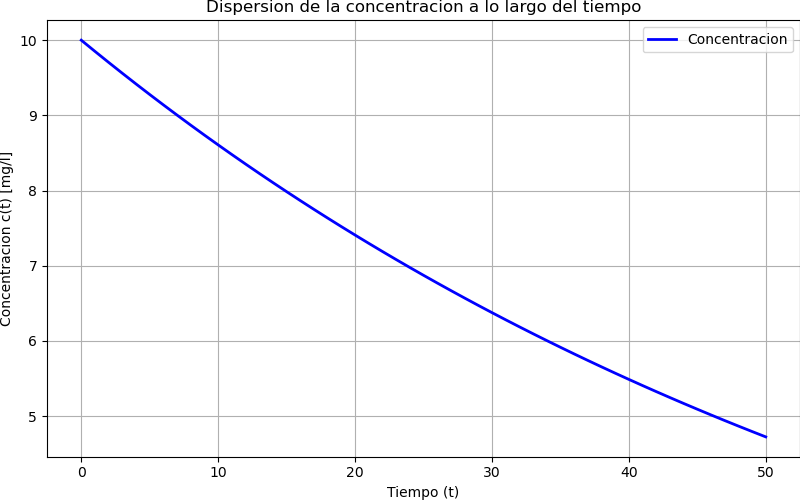

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de parámetros
r = 0.015           # Tasa de decaimiento
c0 = 10.0           # Concentración inicial (mg/l)
pasos = 50          # Número de pasos de tiempo
dt = 1.0            # Tamaño de paso de tiempo

# Vectores para almacenar los resultados (cajas vacías)
c = np.zeros(pasos + 1)
t = np.zeros(pasos + 1)

# Condiciones iniciales (Paso 0)
c[0] = c0
t[0] = 0.0

# Función derivada dc/dt = -rc
def f(c_val):
    return -r * c_val

# 2. Bucle iterativo (Predictor-Corrector / Método de Heun)
for i in range(pasos):
    # a) Predictor (Método de Euler: una suposición simple)
    c_pred = c[i] + f(c[i]) * dt
    
    # b) Corrector (Método del Trapecio: promediamos para ser más exactos)
    c[i+1] = c[i] + (dt / 2.0) * (f(c[i]) + f(c_pred))
    
    # Actualizar tiempo
    t[i+1] = t[i] + dt

# 3. Mostrar resultados finales
print(f'La concentracion final despues de {pasos} pasos es: {c[-1]:.4f} mg/l')

# 4. Representación gráfica
plt.figure(figsize=(8, 5))
plt.plot(t, c, '-b', linewidth=2, label='Concentracion')
plt.grid(True)
plt.xlabel('Tiempo (t)')
plt.ylabel('Concentracion c(t) [mg/l]')
plt.title('Dispersion de la concentracion a lo largo del tiempo')
plt.legend()
plt.show()

### Explicacion del codigo
#### 1. Entrada de datos / parametros
```
```